# Dementia Care Robot - Component 1

### Notebook Structure

1. Component Introduction and Objective
2. Env and Library Setup
3. Dataset Loading
4. Dataset Structure Inspection
5. Data Quality Assessment
6. Exploratory Data Analysis (EDA)
7. Image Visualization & Analysis
8. Data Preprocessing
9. Feature Engineering / Feature Extraction
10. Train, Validation and Test Preparation
11. Final Dataset Verfication

-------------

### 1. Component 1 Overview

This notebook focuses on the Data Science workflow for preparing
the FER-2013 dataset for facial expression recognition.

The objective is to explore, analyse, clean, preprocess, and
prepare facial image data for developing a machine learning
model capable of classifying facial expressions into seven
categories.

### Dataset
FER-2013 – Facial Expression Recognition 2013

### Emotion Categories
1. Angry
2. Disgust
3. Fear
4. Happy
5. Neutral
6. Sad
7. Surprise

### Dataset Characteristics
- Image dimensions: 48 × 48 pixels
- Image format: JPG
- Image type: Grayscale
- Learning type: Supervised Learning
- Problem type: Multi-class Classification

---------

### 2. Environment Setup

In [31]:
%pip install numpy pandas matplotlib seaborn scikit-learn pillow opencv-python scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
# Data Manipulation
import os
import numpy as np
import pandas as pd

# Image Processing
from PIL import Image
import cv2

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Splitting 
from sklearn.model_selection import train_test_split

# Feature Extraction
from skimage.feature import hog, local_binary_pattern

# Data Quality
import hashlib
from collections import Counter

# Ignore unneccessary Warning
import warnings
warnings.filterwarnings('ignore')

# Visualization Settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


-------

### 3. Dataset Loading

In [33]:
# Get the working directory
BASE_PATH = os.getcwd()

# Define dataset directoru
DATASET_PATH = os.path.join(BASE_PATH, "dataset")

# Define traning and testing directories
TRAIN_PATH = os.path.join(DATASET_PATH, "train")
TRAIN_IMAGES_PATH = os.path.join(DATASET_PATH, "test")

# Verify Dataset Paths
print("Project Directory: ", BASE_PATH)
print("Dataset Directory: ", DATASET_PATH)

if os.path.exists(DATASET_PATH):
    print("\nDataset found successfully!")

else:
    print("\nDataset not found. Check the directory path.")

Project Directory:  e:\iit\Y2_S1\CM2603 Data Science Group Project\DementiaCareRobot
Dataset Directory:  e:\iit\Y2_S1\CM2603 Data Science Group Project\DementiaCareRobot\dataset

Dataset found successfully!


-----------

### 4. Dataset Structure Inspection

In [34]:
for root, dirs, files in os.walk(DATASET_PATH):

    level = root.replace(DATASET_PATH, '').count(os.sep)

    indent = '    ' * level

    print(f"{indent}{os.path.basename(root)}/")

    if level >= 2:
        continue

    for file in files[:5]:
        print(f"{indent}    {file}")

dataset/
    test/
        angry/
        disgust/
        fear/
        happy/
        neutral/
        sad/
        surprise/
    train/
        angry/
        disgust/
        fear/
        happy/
        neutral/
        sad/
        surprise/


In [35]:
EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

print("Emotions Categories: ", EMOTIONS)
print("Total Classes: ", len(EMOTIONS))

Emotions Categories:  ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Total Classes:  7


In [36]:
data = []

for split in ['train', 'test']:

    split_path = os.path.join(DATASET_PATH, split)

    for emotion in EMOTIONS:

        emotion_path = os.path.join(split_path, emotion)

        for image_file in os.listdir(emotion_path):

            if image_file.lower().endswith(('.png', '.jpg', '.jpeg')):

                data.append({
                    'image_path': os.path.join(emotion_path, image_file),
                    'filename': image_file,
                    'emotion': emotion,
                    'split': split
                })

# Convert into a Pandas DataFrame

df = pd.DataFrame(data)

print("Dataset metadata loaded successfully!")

print("Total Images: ", len(df))

df.head()

Dataset metadata loaded successfully!
Total Images:  35887


,image_path,filename,emotion,split
0,e:\iit\Y2_S1\CM2603 Data Science Group Project...,Training_10118481.jpg,angry,train
1,e:\iit\Y2_S1\CM2603 Data Science Group Project...,Training_10120469.jpg,angry,train
2,e:\iit\Y2_S1\CM2603 Data Science Group Project...,Training_10131352.jpg,angry,train
3,e:\iit\Y2_S1\CM2603 Data Science Group Project...,Training_10161559.jpg,angry,train
4,e:\iit\Y2_S1\CM2603 Data Science Group Project...,Training_1021836.jpg,angry,train


In [37]:
print("Dataset Shape: ", df.shape)

print("\nDataset Information:")
df.info()

print("\Emotion Distribution:")
print(df['emotion'].value_counts())

print("\nTrain/Test Distribution:")
print(df['split'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:  (35887, 4)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  35887 non-null  str  
 1   filename    35887 non-null  str  
 2   emotion     35887 non-null  str  
 3   split       35887 non-null  str  
dtypes: str(4)
memory usage: 1.1 MB
\Emotion Distribution:
emotion
happy       8989
neutral     6198
sad         6077
fear        5121
angry       4953
surprise    4002
disgust      547
Name: count, dtype: int64

Train/Test Distribution:
split
train    28709
test      7178
Name: count, dtype: int64

Missing Values:
image_path    0
filename      0
emotion       0
split         0
dtype: int64


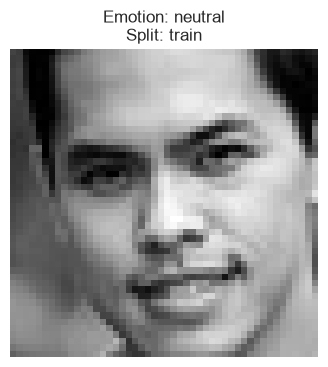

In [38]:
# Select one random image
sample = df.sample(1, random_state=42).iloc[0]

# Load the image
image = Image.open(sample['image_path'])

#Display the image
plt.figure(figsize=(4, 4))

plt.imshow(image, cmap='gray')

plt.title(
    f"Emotion: {sample['emotion']}\nSplit: {sample['split']}"
)

plt.axis('off')

plt.show()

-----

### 5. Data Quality Assessment

--------

### 6. Explotary Data Analysis (EDA)

--------------

### 7. Image Visualization and Analysis

-------------

### 8. Data Preprocessing

-------------

### 9. Feature Engineering / Feature Extraction

-----------

### 10. Train, Validation & Test Preparation

------------

### 11. Final Dataset Verification

------------